# 03b · Earth Engine enrichment layers
28 label-free covariates added from Google Earth Engine (`src/extract_enrichment_gee.py`): ESA WorldCover fractions,
Hansen forest cover and loss, SoilGrids, MODIS NDVI and ET dynamics, CHIRPS trends, GHSL built-up, WorldPop,
VIIRS night lights and ALOS landforms. This notebook checks coverage, agreement with the survey's own land-use record
and univariate association with drying. (Re-extraction needs an authenticated Earth Engine account.)

In [1]:
import sys, os, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 80)
M, F = ROOT / "results/metrics", ROOT / "results/figures"
def table(name, **kw):
    t = pd.read_csv(M / name, **kw)
    return t.round(4)
def fig(name, width=1100):
    display(Image(filename=str(F / name), width=width))

In [2]:
from src.graph_builder import load_master
from src.features import ENRICHMENT, DYNAMIC_FEATURES, check_feature_set
from sklearn.metrics import roc_auc_score
df = load_master()
print("leakage check env_rich:", check_feature_set(df, "env_rich") or "clean")
df[ENRICHMENT].describe().T.round(3)

leakage check env_rich: clean


,count,mean,std,min,25%,50%,75%,max
wc_tree,5689.0,0.621,0.261,0.001,0.441,0.665,0.834,1.000
wc_shrub,5689.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000
wc_grass,5689.0,0.110,0.132,0.000,0.023,0.061,0.144,0.928
wc_crop,5689.0,0.233,0.224,0.000,0.048,0.163,0.363,0.996
wc_built,5689.0,0.033,0.080,0.000,0.000,0.006,0.026,0.642
wc_bare,5689.0,0.003,0.015,0.000,0.000,0.000,0.000,0.362
wc_water,5689.0,0.001,0.010,0.000,0.000,0.000,0.000,0.172
gfc_treecover2000,5689.0,24.242,20.417,0.000,6.736,19.402,37.949,89.024
gfc_loss_pre2015,5689.0,0.003,0.009,0.000,0.000,0.000,0.004,0.134
gfc_loss_post2015,5689.0,0.006,0.019,0.000,0.000,0.000,0.000,0.462


## Agreement with the survey-recorded land use

In [3]:
pairs = [("landuse_agriculture", "wc_crop"), ("landuse_dense_forest", "wc_tree"), ("landuse_sparse_forest", "wc_tree"),
         ("landuse_settlement", "wc_built"), ("landuse_grassland", "wc_grass")]
pd.DataFrame([{"survey class": a, "WorldCover fraction": b, "AUC": roc_auc_score(df[a], df[b].fillna(0))} for a, b in pairs]).round(3)

,survey class,WorldCover fraction,AUC
0,landuse_agriculture,wc_crop,0.747
1,landuse_dense_forest,wc_tree,0.763
2,landuse_sparse_forest,wc_tree,0.618
3,landuse_settlement,wc_built,0.785
4,landuse_grassland,wc_grass,0.565


## Univariate association with drying (AUC; 0.5 = none)

In [4]:
y = df.target_dried
auc = pd.Series({c: roc_auc_score(y, df[c].fillna(df[c].median())) for c in ENRICHMENT}).rename("AUC").to_frame()
auc["dynamic (may reflect drying)"] = auc.index.isin(DYNAMIC_FEATURES)
auc.assign(strength=(auc.AUC - 0.5).abs()).sort_values("strength", ascending=False).round(3)

,AUC,dynamic (may reflect drying),strength
soil_bdod,0.608,False,0.108
landform_position,0.605,False,0.105
mtpi,0.591,False,0.091
wc_tree,0.420,False,0.080
gfc_treecover2000,0.427,False,0.073
soil_soc,0.431,False,0.069
et_mean,0.433,False,0.067
wc_built,0.563,False,0.063
wc_crop,0.550,False,0.050
ndvi_trend,0.546,True,0.046


## Drying by ALOS slope position (1 valley … 4 ridge/peak)

In [5]:
df.groupby("landform_position").target_dried.agg(["size", "mean"]).round(3)

,size,mean
landform_position,,
1,703,0.171
2,2817,0.217
3,2065,0.356
4,104,0.538


## Maps of selected layers

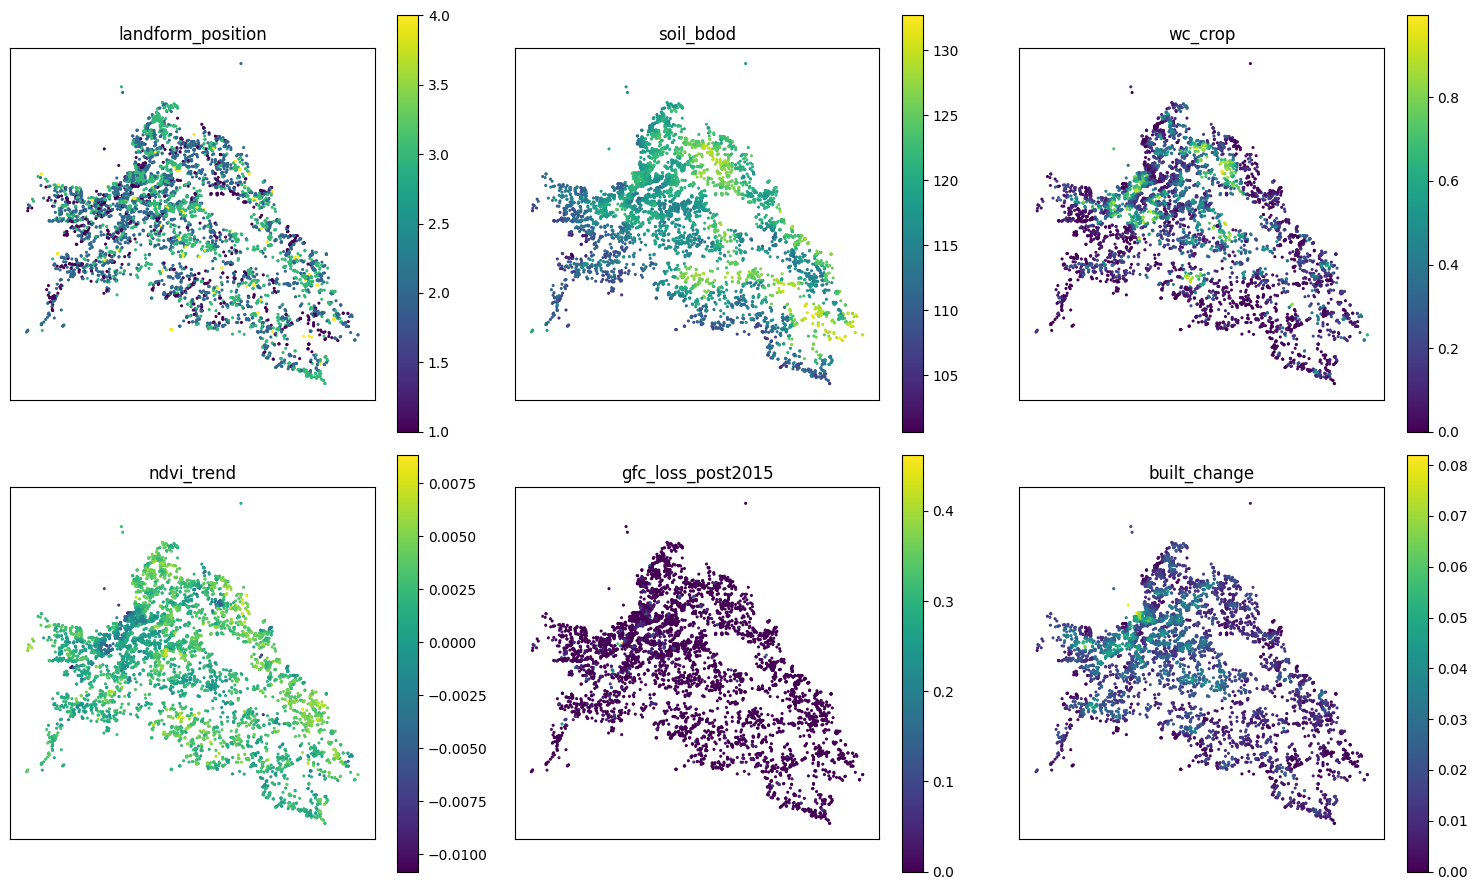

In [6]:
cols = ["landform_position", "soil_bdod", "wc_crop", "ndvi_trend", "gfc_loss_post2015", "built_change"]
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, c in zip(axes.ravel(), cols):
    sc = ax.scatter(df.longitude, df.latitude, c=df[c], s=1.5, cmap="viridis"); ax.set_title(c); plt.colorbar(sc, ax=ax)
    ax.set_aspect(1 / np.cos(np.radians(27.57))); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()